# Who is still uncovered by health insurance in Rwanda?
### A step-by-step classification pipeline: traditional ML vs deep learning

**Data:** EICV7 2023-24 household survey (NISR). **Question:** given what a survey tells us about a person and their household, can we predict who is *not* covered by health insurance?.

### The pipeline at a glance

| Steps | What happens | Rubric area it supports |
|---|---|---|
| 0-2 | Install, settings, load the two survey files | Reproducibility |
| 3-6 | Build the target, remove leakage, add features, pick columns | Preprocessing and feature engineering |
| 7-8 | Split by household, build the helper functions | Evaluation set-up |
| 9 | Traditional ML experiments (scikit-learn) | Model implementation |
| 10 | Deep learning experiments (Keras + `tf.data`) | Model implementation |
| 11-12 | Results table, pick the best two models, final test | Experiment table |
| 13-14 | Confusion matrices, ROC, learning curves, subgroup errors, feature importance | Evaluation and error analysis |
| 15 | Save models and outputs | Deliverables |

### Code rules for this notebook
1. All imports live in one cell (Step 0).
2. Every setting you might change lives in one cell (Step 1).
3. Variables have names that say what they hold (`train_df`, not `t`).
4. Every function has type hints and does one job.
5. Every experiment goes through **one** function per family (`run_sklearn_experiment`, `run_keras_experiment`), so the results table is built the same way every time.

## Step 0: Install and import

**What:** install the libraries, then import everything once.
**Why:** a notebook that installs its own dependencies runs on any machine, which the rubric calls *reproducibility*. In Colab, run the install cell first and restart the runtime if it asks you to.

In [ ]:
!pip install -q -U scikit-learn pandas numpy scipy matplotlib tensorflow tensorboard pyreadstat joblib

In [ ]:
import os
import re
import random
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras

from scipy.stats import loguniform, randint
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay,
                             average_precision_score, confusion_matrix, f1_score,
                             precision_recall_curve, precision_score, roc_auc_score)
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, RandomizedSearchCV, learning_curve
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.utils.class_weight import compute_sample_weight

warnings.filterwarnings("ignore")
print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


## Step 1: Settings and random seeds

**What:** put every value you might want to change in one place.
**Why:** if a number is buried inside a function, nobody can find it later. Fixing the random seed means you get the same results every time you re-run, which is what lets you quote numbers in your report.

The three **CONFIRM** values are survey codes. Open the NISR questionnaire and check that `1` really means "covered" for `s3q2` and "ill" for `s3q4`.

The four "run size" values only control speed. Lower them for a quick test run, then set them back for your final run.

In [ ]:
SEED = 42
PERSON_PATH = "data/person.dta"
POVERTY_PATH = "data/poverty.dta"
HOUSEHOLD_ID = "hhid"
COVERED_CODE = 1
TARGET = "uncovered"
TARGET_RECALL = 0.90

N_SEARCH_ITER = 12
DL_EPOCHS = 40
LC_SUBSAMPLE = 15000
PERM_SUBSAMPLE = 8000

def set_all_seeds(seed: int = SEED) -> None:

    random.seed(seed)
    np.random.seed(seed)
    tf.keras.utils.set_random_seed(seed)

set_all_seeds()
for folder in ["models", "logs", "outputs"]:
    os.makedirs(folder, exist_ok=True)

## Step 2: Load the data

**What:** read two files. `person` has one row per person (about 62,000 rows). `poverty` has one row per household (about 15,000 rows) with welfare information.
**Why:** insurance is recorded per person, but poverty and consumption are recorded per household. We will join them in Step 5.

`load_table` also returns the *variable labels*, which are the human-readable descriptions of each column. We use them in Step 3 to find the right columns.

In [ ]:
def load_table(path: str) -> tuple[pd.DataFrame, dict[str, str]]:
    extension = os.path.splitext(path)[1].lower()
    labels: dict[str, str] = {}

    if extension == ".dta":
        with pd.read_stata(path, iterator=True, convert_categoricals=False) as reader:
            labels = reader.variable_labels()
            table = reader.read()
    elif extension == ".sav":
        import pyreadstat
        table, meta = pyreadstat.read_sav(path, apply_value_formats=False)
        labels = dict(zip(meta.column_names, meta.column_labels))
    elif extension == ".csv":
        table = pd.read_csv(path, low_memory=False)
    else:
        raise ValueError(f"Unsupported file type: {extension}")

    table.columns = [c.lower() for c in table.columns]
    labels = {k.lower(): (v or "") for k, v in labels.items()}
    return table, labels

In [ ]:

PERSON_PATH = "/content/CS_S0_S1_S2_S3_S4_S6A_S6B_S6C_Person.dta"
POVERTY_PATH = "/content/CS_EICV7_poverty_file.dta"

person, person_labels = load_table(PERSON_PATH)
poverty, poverty_labels = load_table(POVERTY_PATH)

print("Person rows:", len(person), "(catalog says about 62,110)")
print("Household rows:", len(poverty), "(catalog says about 15,054)")

Person rows: 62110 (catalog says about 62,110)
Household rows: 15054 (catalog says about 15,054)


## Step 3: Choose the key columns and build the target

**What:** first we find which column holds age, sex, and so on; and then we create the target column `uncovered`.
**Why:** column names in survey files are cryptic (`s3q2`). Searching the labels is safer than guessing.

The search below prints candidate columns for each topic. Read them, then set the five names in the next cell. **CONFIRM** each choice.

In [ ]:
def find_columns(labels: dict[str, str], pattern: str) -> list[str]:
    regex = re.compile(pattern, re.I)
    return [col for col, label in labels.items() if regex.search(f"{col} {label}")]

searches = {"age": r"\bage\b", "sex": r"\bsex\b|gender", "urban/rural": r"urban|rural|residence",
            "district": r"district", "province": r"province"}
for topic, pattern in searches.items():
    print(f"{topic:12s} ->", find_columns(person_labels, pattern)[:8])

age          -> ['s1q3y', 's1q3m', 's4aq9']
sex          -> ['s1q1']
urban/rural  -> ['ur']
district     -> ['district', 's1q5b', 's2q2', 's2q4b']
province     -> ['province']


In [ ]:
def check_column(name: str, table: pd.DataFrame) -> str | None:
    if name in table.columns:
        return name
    print(f"WARNING: column {name!r} not found, it will be skipped")
    return None
AGE_COL = check_column("s1q3y", person)
SEX_COL = check_column("s1q1", person)
URBAN_COL = check_column("ur", person)
DISTRICT_COL = check_column("district", person)
PROVINCE_COL = check_column("province", person)

In [ ]:
print(person_labels["s1q1"], "|", person_labels["s1q3y"])
print(person["s1q1"].value_counts())

Sex | Age (Years)
s1q1
2    32435
1    29675
Name: count, dtype: int64


In [ ]:
with pd.read_stata(PERSON_PATH, iterator=True) as reader:
    label_sets = reader.value_labels()

for name, mapping in label_sets.items():
    if any("male" in str(v).lower() for v in mapping.values()):
        print(name, mapping)

S1Q1 {np.int32(1): 'Male', np.int32(2): 'Female'}


### The target

`s3q2` says whether a person is covered. We turn it into a simple yes/no column, `uncovered` (1 = not covered). People with a missing answer get a missing target and are dropped later.

Look at the value counts first so you know what the codes mean before you trust the conversion.

In [ ]:
for question in ["s3q2", "s3q3", "s3q4", "s3q5", "s3q5a"]:
    if question in person.columns:
        print(f"\n--- {question}: {person_labels.get(question, '')} ---")
        print(person[question].value_counts(dropna=False).sort_index())


--- s3q2: Is [name] currently covered by any health insurance? ---
s3q2
1    53149
2     8909
3       52
Name: count, dtype: int64

--- s3q3: Main health insurance carry ---
s3q3
1.0    49310
2.0     2417
3.0      828
4.0       26
5.0       73
6.0      421
7.0       70
8.0        4
NaN     8961
Name: count, dtype: int64

--- s3q4: Suffer from an illness or injury over the last 4weeks ---
s3q4
1    16801
2    45309
Name: count, dtype: int64

--- s3q5: Medical consultation in the over last 4 weeks ---
s3q5
1    13763
2      282
3    47986
4       79
Name: count, dtype: int64

--- s3q5a: why not consult any Medical profession ---
s3q5a
1.0     3180
2.0       50
3.0      131
4.0       37
5.0        5
6.0       19
7.0      557
8.0      773
9.0       74
NaN    57284
Name: count, dtype: int64


In [ ]:
NOT_COVERED_CODE = 2

known = person["s3q2"].isin([COVERED_CODE, NOT_COVERED_CODE])
person[TARGET] = np.where(known, (person["s3q2"] == NOT_COVERED_CODE).astype(float), np.nan)

print("People with another code, dropped:", int((~known & person["s3q2"].notna()).sum()))
print("Share uncovered:", round(person[TARGET].mean(), 3), "(NISR reports 85.3% coverage, so about 0.15 expected)")

People with another code, dropped: 52
Share uncovered: 0.144 (NISR reports 85.3% coverage, so about 0.15 expected)


In [ ]:
with pd.read_stata(PERSON_PATH, iterator=True) as reader:
    label_sets = reader.value_labels()
print({k: v for k, v in label_sets.items() if k.lower() == "s3q2"})

{'S3Q2': {np.int32(1): 'Yes', np.int32(2): 'No', np.int32(3): "Don't know"}}


### Why this problem matters

Among people who were ill, does coverage change whether they sought care? This is the motivation for the whole project, so keep the table for your introduction. **CONFIRM** the codes of `s3q4` and `s3q5`.

In [ ]:
ILL_CODE = 1
ill_people = person[person["s3q4"] == ILL_CODE]
print("People reporting illness:", len(ill_people), "(catalog says 16,801)")
print(pd.crosstab(ill_people[TARGET], ill_people["s3q5"], normalize="index").round(3))

People reporting illness: 16801 (catalog says 16,801)
s3q5           1      2      3      4
uncovered                            
0.0        0.741  0.014  0.244  0.001
1.0        0.399  0.033  0.567  0.000


## Step 4: Remove leakage

**What:** list the columns that must *not* be used as features.
**Why:** *leakage* means a feature contains the answer, or something that only exists because of the answer. A model that sees it looks brilliant in testing and is useless in real life.

In this survey:
- `s3q3` (type of insurance) is only answered by covered people, so it gives the target away.
- `s3q5a` (reasons for not consulting) and `s3q6` (reasons for consulting) come *after* the outcome.
- Any column whose label mentions insurance, mutuelle, CBHI, RSSB, MMI or premiums is suspect.

The code below finds these automatically. Print the Section 3 columns and add any others you spot to `EXTRA_EXCLUDE`.

In [ ]:
section3_columns = [c for c in person.columns if c.startswith("s3q")]
print("Section 3 columns to review:", section3_columns)

EXTRA_EXCLUDE: list[str] = []
LEAK_NAME_PATTERN = re.compile(r"^s3q(2|3|5|6)[a-z]?$")
LEAK_LABEL_PATTERN = re.compile(r"insur|mutuel|cbhi|rssb|\bmmi\b|premium", re.I)
all_labels = {**poverty_labels, **person_labels}

def find_leakage_columns(columns) -> list[str]:
    by_name = {c for c in columns if LEAK_NAME_PATTERN.match(c)}
    by_label = {c for c in columns if LEAK_LABEL_PATTERN.search(all_labels.get(c, ""))}
    return sorted(by_name | by_label | set(EXTRA_EXCLUDE))

Section 3 columns to review: ['s3q2', 's3q3', 's3q4', 's3q5', 's3q5a', 's3q6', 's3q7', 's3q8', 's3q9', 's3q10', 's3q11', 's3q12']


## Step 5: Engineer household features and merge welfare data

**What:** first we  count things about each person's household, such as its size and how many young children it has; second we join the household poverty file onto every person.
**Why:** insurance is often decided at household level (one family paying for the whole family), so household context should help the model. Notice the new features are built from **age and household id only, never from the target**.

| New feature | Meaning |
|---|---|
| `hh_size_calc` | number of people in the household |
| `hh_children_u5` | children under 5 in the household |
| `hh_elderly_60p` | people aged 60 or over |
| `age_band` | age grouped into 7 bands |

In [ ]:
def add_household_features(df: pd.DataFrame, age_col: str | None, household_id: str) -> pd.DataFrame:
    out = df.copy()
    out["hh_size_calc"] = out.groupby(household_id)[household_id].transform("size")
    if age_col is not None:
        age = out[age_col]
        out["hh_children_u5"] = (age < 5).groupby(out[household_id]).transform("sum")
        out["hh_elderly_60p"] = (age >= 60).groupby(out[household_id]).transform("sum")
        out["age_band"] = pd.cut(age, [-1, 4, 14, 24, 34, 49, 64, 200], labels=False)
    return out

person_fe = add_household_features(person, AGE_COL, HOUSEHOLD_ID)
ENGINEERED = [c for c in ["hh_size_calc", "hh_children_u5", "hh_elderly_60p", "age_band"] if c in person_fe.columns]
print("Engineered features:", ENGINEERED)

Engineered features: ['hh_size_calc', 'hh_children_u5', 'hh_elderly_60p', 'age_band']


In [ ]:
data = person_fe.merge(poverty, on=HOUSEHOLD_ID, how="left", suffixes=("", "_hh"))

GEOGRAPHY = {"province", "district", "ur", "clust"}
welfare_names = set(poverty.columns) - {HOUSEHOLD_ID} - GEOGRAPHY
welfare_cols = [c for c in data.columns
                if c in welfare_names or (c.endswith("_hh") and c[:-3] in welfare_names)]
DUPLICATE_GEOGRAPHY = [f"{g}_hh" for g in GEOGRAPHY if f"{g}_hh" in data.columns]

print("Rows after merge:", len(data), "(must equal the person file:", len(person), ")")
print("Welfare columns merged:", welfare_cols[:12], "...")
if welfare_cols:
    print("Household match rate:", round(data[welfare_cols[0]].notna().mean(), 3))

Rows after merge: 62110 (must equal the person file: 62110 )
Welfare columns merged: ['weight', 'epov_jan', 'pov_jan', 'poverty', 'quintile', 'ae', 'member', 'food_at_school', 'exp1', 'exp2', 'exp3', 'exp4'] ...
Household match rate: 1.0


## Step 6: Select the features

**What:** decide automatically which columns are *numeric* and which are *categorical*, skipping leakage, id columns, columns that are mostly empty, and columns with a single value.
**Why:** a survey has hundreds of columns. Rules written as code are reproducible and easy to explain in a report.

| Rule | Reason |
|---|---|
| drop leakage columns and the target | see Step 4 |
| drop id and weight columns | an id carries no real information |
| drop columns more than 60% missing | too little to learn from |
| text columns with up to 60 values become categorical | one-hot encoding stays manageable |
| whole-number columns with up to 25 values become categorical | codes like 1/2/3 are labels, not quantities |
| everything else is numeric | |

In [ ]:
ID_LIKE = re.compile(r"(^|_)(id|pid|wt|weight)(_|$)|^hhid|^pop_wt|^hh_?number|^clust(_hh)?$|^hh_index$", re.I)
FORCE_NUMERIC = {c for c in ENGINEERED if c != "age_band"} | ({AGE_COL} if AGE_COL else set())
FORCE_CATEGORICAL = {"district", "s1q5b"}

def is_text_column(series: pd.Series) -> bool:
    return series.dtype == object or str(series.dtype) in ("string", "str", "category")

def select_features(df: pd.DataFrame, exclude: set[str],
                    max_missing: float = 0.6, max_cardinality: int = 60) -> tuple[list[str], list[str]]:
    numeric, categorical = [], []
    for col in df.columns:
        if col in exclude or ID_LIKE.search(col):
            continue
        series = df[col]
        n_unique = series.nunique(dropna=True)
        if series.isna().mean() > max_missing or n_unique < 2:
            continue
        if col in FORCE_CATEGORICAL:
            categorical.append(col)
        elif col in FORCE_NUMERIC:
            numeric.append(col)
        elif is_text_column(series):
            if n_unique <= max_cardinality:
                categorical.append(col)
        elif n_unique <= 25 and np.allclose(series.dropna() % 1, 0):
            categorical.append(col)
        else:
            numeric.append(col)
    return numeric, categorical

In [ ]:
leakage_columns = find_leakage_columns(data.columns)
excluded = set(leakage_columns) | {TARGET, HOUSEHOLD_ID} | set(DUPLICATE_GEOGRAPHY)

data = data.dropna(subset=[TARGET]).reset_index(drop=True)
NUM_COLS, CAT_COLS = select_features(data, excluded)
ALL_FEATURES = NUM_COLS + CAT_COLS

print("Excluded as leakage:", leakage_columns)
print(f"Selected {len(NUM_COLS)} numeric and {len(CAT_COLS)} categorical features")
print("Numeric:", NUM_COLS)
print("Categorical:", CAT_COLS)

Excluded as leakage: ['s3q2', 's3q3', 's3q5', 's3q5a', 's3q6']
Selected 23 numeric and 58 categorical features
Numeric: ['s1q3y', 's6bq1', 's6bq2', 'hh_size_calc', 'hh_children_u5', 'hh_elderly_60p', 'ae', 'food_at_school', 'exp1', 'exp2', 'exp3', 'exp4', 'exp5', 'exp6', 'exp7', 'exp8', 'exp9', 'exp10', 'exp11', 'sol_jan', 'food', 'cons1', 'cons1ae']
Categorical: ['province', 'district', 'ur', 's1q1', 's1q2', 's1q4', 's1q5a', 's1q5b', 's1q6', 's1q7a', 's1q10', 's1q12', 's1q13', 's2q2', 's3q4', 's3q7', 's3q8', 's3q9', 's3q10', 's3q11', 's3q12', 's4aq1', 's4aq2', 's4aq2a', 's4aq6a', 's4aq6b', 's4aq7', 's4bq1', 's4bq4', 's4bq5', 's4bq6', 's4bq7', 's4bq8', 's4bq13a', 's4bq13b', 's4bq15', 's4bq16', 's6aq2', 's6aq4', 's6aq5', 's6aq6', 's6aq7', 's6aq8', 's6bq3', 's6bq4', 's6bq5', 's6bq7', 'epov_jan', 'pov_jan', 'poverty', 'quintile', 'ed_foodgov', 'age_band', 'member', 'quintile_hh', 'pov_jan_hh', 'poverty_hh', 'epov_jan_hh']


In [ ]:

by_quintile = data.groupby("quintile")[TARGET].agg(uncovered_rate="mean", people="size").round(3)
print(by_quintile)

for col in ["exp6", "exp11"]:
    if col in data.columns:
        decile = pd.qcut(data[col], 10, labels=False, duplicates="drop")
        print(f"\nUncovered rate by {col} decile (0 = lowest):")
        print(data.groupby(decile)[TARGET].mean().round(3).to_string())

          uncovered_rate  people
quintile                        
1.0                0.233   12561
2.0                0.177   12691
3.0                0.134   12681
4.0                0.101   12354
5.0                0.068   11771

Uncovered rate by exp6 decile (0 = lowest):
exp6
0    0.331
1    0.210
2    0.185
3    0.140
4    0.124
5    0.118
6    0.096
7    0.090
8    0.081
9    0.060

Uncovered rate by exp11 decile (0 = lowest):
exp11
0.0    0.332
1.0    0.220
2.0    0.178
3.0    0.143
4.0    0.129
5.0    0.108
6.0    0.105
7.0    0.069
8.0    0.066
9.0    0.043


## Step 7: Split into train, validation and test, by household

**What:** split the data 70% train, 15% validation, 15% test, keeping every household entirely in one part.
**Why:** people in the same household share income, location and (often) insurance. If one family member is in training and another in testing, the model just recognises the family, and the test score is too optimistic. This is a form of leakage too. `GroupShuffleSplit` keeps households together.

The three parts have different jobs:
- **train**: the model learns from it
- **validation**: we compare experiments and tune settings on it
- **test**: touched **once**, at the very end (Step 12)

📖 [GroupShuffleSplit docs](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GroupShuffleSplit.html)

In [ ]:
def grouped_split(df: pd.DataFrame, test_size: float, seed: int = SEED) -> tuple[pd.DataFrame, pd.DataFrame]:
    splitter = GroupShuffleSplit(n_splits=1, test_size=test_size, random_state=seed)
    first_idx, second_idx = next(splitter.split(df, df[TARGET], df[HOUSEHOLD_ID]))
    return df.iloc[first_idx].reset_index(drop=True), df.iloc[second_idx].reset_index(drop=True)

train_val_df, test_df = grouped_split(data, 0.15)
train_df, val_df = grouped_split(train_val_df, 0.1765)

y_val = val_df[TARGET].values.astype(int)
y_test = test_df[TARGET].values.astype(int)

In [ ]:
for name, part in [("train", train_df), ("val", val_df), ("test", test_df)]:
    print(f"{name:5s}: {len(part):6d} rows, {part[HOUSEHOLD_ID].nunique():5d} households, uncovered share {part[TARGET].mean():.3f}")

shared = (set(train_df[HOUSEHOLD_ID]) & set(val_df[HOUSEHOLD_ID])) \
       | (set(train_df[HOUSEHOLD_ID]) & set(test_df[HOUSEHOLD_ID])) \
       | (set(val_df[HOUSEHOLD_ID]) & set(test_df[HOUSEHOLD_ID]))
print("Households shared between splits:", len(shared), "(must be 0)")

train:  43503 rows, 10534 households, uncovered share 0.146
val  :   9290 rows,  2258 households, uncovered share 0.137
test :   9265 rows,  2258 households, uncovered share 0.138
Households shared between splits: 0 (must be 0)


## Step 8: Helper functions

Four small tools that every experiment reuses. Defining them once is what keeps the experiment table consistent.

### 8.1 Preprocessing

Models need clean numbers, so each column type gets its own treatment:

| Column type | Missing values | Then |
|---|---|---|
| numeric | filled with the median, plus a "was missing" flag | scaled to mean 0, spread 1 |
| categorical | filled with the most common value, plus a flag | one-hot encoded (rare values grouped together) |

Putting this inside a `ColumnTransformer` means it is *fitted on the training rows only* and then applied to validation and test, so no information leaks across the split.

📖 [ColumnTransformer docs](https://scikit-learn.org/stable/modules/compose.html#column-transformer)

In [ ]:
def make_preprocessor(num_cols: list[str], cat_cols: list[str]) -> ColumnTransformer:
    numeric_steps = Pipeline([
        ("fill", SimpleImputer(strategy="median", add_indicator=True)),
        ("scale", StandardScaler()),
    ])
    categorical_steps = Pipeline([
        ("fill", SimpleImputer(strategy="most_frequent", add_indicator=True)),
        ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=30, sparse_output=False)),
    ])
    return ColumnTransformer([("num", numeric_steps, num_cols),
                              ("cat", categorical_steps, cat_cols)], remainder="drop")

### 8.2 Metrics

With only ~15% positives, accuracy is misleading, so we report:

| Metric | In plain words |
|---|---|
| **sensitivity** (recall) | of the people who are really uncovered, how many did we find? |
| **specificity** | of the people who are really covered, how many did we correctly leave alone? |
| **precision** | of the people we flagged, how many were really uncovered? |
| **ROC-AUC** | how well the model ranks uncovered above covered, over all thresholds |
| **PR-AUC** | like ROC-AUC but focused on the rare class; **our main selection metric** |

📖 [Metrics in scikit-learn](https://scikit-learn.org/stable/modules/model_evaluation.html)

### 8.3 The decision threshold

A model outputs a probability. The default cut-off of 0.5 is rarely right for an imbalanced problem. `threshold_for_recall` finds the **highest** cut-off that still catches at least `TARGET_RECALL` (90%) of uncovered people on the validation set. Higher cut-off means fewer false alarms.

In [ ]:
def evaluate(y_true: np.ndarray, proba: np.ndarray, threshold: float = 0.5) -> dict:
    predicted = (proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, predicted, labels=[0, 1]).ravel()
    return {
        "threshold": round(float(threshold), 4),
        "sensitivity": tp / (tp + fn) if (tp + fn) else np.nan,
        "specificity": tn / (tn + fp) if (tn + fp) else np.nan,
        "precision": precision_score(y_true, predicted, zero_division=0),
        "f1": f1_score(y_true, predicted, zero_division=0),
        "roc_auc": roc_auc_score(y_true, proba),
        "pr_auc": average_precision_score(y_true, proba),
        "tp": int(tp), "fp": int(fp), "fn": int(fn), "tn": int(tn),
    }

def threshold_for_recall(y_true: np.ndarray, proba: np.ndarray, target: float = TARGET_RECALL) -> float:
    precision, recall, thresholds = precision_recall_curve(y_true, proba)
    reaches_target = np.where(recall[:-1] >= target)[0]
    return float(thresholds[reaches_target[-1]]) if len(reaches_target) else 0.0

### 8.4 The experiment log

Every experiment calls `log_result`, which does two things: it adds one row to the **results table** (`RESULTS`) and writes the same numbers to **TensorBoard** (`logs/`). This is how each number in your report can be traced back to a logged run, which the rubric asks for.

📖 [TensorBoard getting started](https://www.tensorflow.org/tensorboard/get_started)

In [ ]:
RESULTS: list[dict] = []
SKLEARN_MODELS: dict = {}
FEATURES_USED: dict = {}
KERAS_MODELS: dict = {}
HISTORIES: dict = {}

def log_to_tensorboard(exp_id: str, metrics: dict) -> None:
    writer = tf.summary.create_file_writer(f"logs/{exp_id}")
    with writer.as_default():
        for name, value in metrics.items():
            if isinstance(value, (int, float, np.floating)) and not np.isnan(value):
                tf.summary.scalar(name, float(value), step=0)
    writer.flush()

def log_result(exp_id: str, family: str, name: str, settings: str, n_features: int,
               proba_val: np.ndarray, notes: str = "") -> dict:
    threshold = threshold_for_recall(y_val, proba_val)
    at_half = evaluate(y_val, proba_val, 0.5)
    at_target = evaluate(y_val, proba_val, threshold)
    row = {
        "exp": exp_id, "family": family, "model": name, "settings": settings,
        "n_features": n_features, "split": "train 70 / val 15 / test 15, grouped by household",
        "val_roc_auc": at_half["roc_auc"], "val_pr_auc": at_half["pr_auc"],
        "val_sens@0.5": at_half["sensitivity"], "val_prec@0.5": at_half["precision"],
        "thr_for_recall": threshold, "val_sens@thr": at_target["sensitivity"],
        "val_spec@thr": at_target["specificity"], "val_prec@thr": at_target["precision"],
        "notes": notes,
    }
    RESULTS.append(row)
    log_to_tensorboard(exp_id, {k: v for k, v in row.items() if k.startswith("val_") or k == "thr_for_recall"})
    return row

## Step 9: Traditional machine learning experiments

### 9.1 One function for every scikit-learn run

`run_sklearn_experiment` builds *preprocessing + model* as a single pipeline, fits it on the training rows, scores it on validation, and logs it. To run a new experiment you only supply a model and a few options:

| Option | Meaning |
|---|---|
| `weighted=True` | give uncovered people a larger weight so the rare class is not ignored |
| `undersample=True` | instead of weights, throw away some covered people (2 covered for every 1 uncovered) |
| `cols=...` | use only some features (for ablation experiments) |

In [ ]:
def undersample_index(y: np.ndarray, majority_to_minority: float = 2.0, seed: int = SEED) -> np.ndarray:
    rng = np.random.default_rng(seed)
    y = np.asarray(y)
    positives, negatives = np.where(y == 1)[0], np.where(y == 0)[0]
    minority, majority = (positives, negatives) if len(positives) <= len(negatives) else (negatives, positives)
    n_keep = min(len(majority), int(len(minority) * majority_to_minority))
    kept_majority = rng.choice(majority, size=n_keep, replace=False)
    return np.sort(np.concatenate([minority, kept_majority]))

def run_sklearn_experiment(exp_id: str, name: str, model, cols: list[str] | None = None,
                           weighted: bool = True, undersample: bool = False,
                           settings: str = "", notes: str = "") -> tuple[Pipeline, np.ndarray]:
    cols = cols or ALL_FEATURES
    num_cols = [c for c in NUM_COLS if c in cols]
    cat_cols = [c for c in CAT_COLS if c in cols]
    pipeline = Pipeline([("prep", make_preprocessor(num_cols, cat_cols)), ("clf", model)])

    X_train, y_train = train_df[cols], train_df[TARGET].values.astype(int)
    if undersample:
        keep = undersample_index(y_train)
        X_train, y_train = X_train.iloc[keep], y_train[keep]

    fit_kwargs = {}
    if weighted and not undersample:
        fit_kwargs["clf__sample_weight"] = compute_sample_weight("balanced", y_train)
    pipeline.fit(X_train, y_train, **fit_kwargs)

    proba_val = pipeline.predict_proba(val_df[cols])[:, 1]
    row = log_result(exp_id, "traditional", name, settings, len(cols), proba_val, notes)
    SKLEARN_MODELS[exp_id], FEATURES_USED[exp_id] = pipeline, cols
    print(f"{exp_id} {name}: val PR-AUC {row['val_pr_auc']:.3f} | "
          f"sensitivity@thr {row['val_sens@thr']:.3f} | precision@thr {row['val_prec@thr']:.3f}")
    return pipeline, proba_val

### 9.2 E1-E3: three different algorithms

We start with three untuned models on the same features, so any difference comes from the *algorithm*, not the settings.

| Exp | Model | Idea |
|---|---|---|
| E1 | Logistic regression | a straight-line boundary; simple and easy to explain, our baseline |
| E2 | Random forest | many decision trees voting; handles non-linear patterns |
| E3 | Gradient boosting (HGB) | trees built one after another, each fixing the last one's mistakes |

In [ ]:
run_sklearn_experiment("E1", "Logistic regression", LogisticRegression(max_iter=2000),
                       settings="balanced weights, default C", notes="Linear baseline")

E1 Logistic regression: val PR-AUC 0.352 | sensitivity@thr 0.901 | precision@thr 0.190


(Pipeline(steps=[('prep',
                  ColumnTransformer(transformers=[('num',
                                                   Pipeline(steps=[('fill',
                                                                    SimpleImputer(add_indicator=True,
                                                                                  strategy='median')),
                                                                   ('scale',
                                                                    StandardScaler())]),
                                                   ['s1q3y', 's6bq1', 's6bq2',
                                                    'hh_size_calc',
                                                    'hh_children_u5',
                                                    'hh_elderly_60p', 'ae',
                                                    'food_at_school', 'exp1',
                                                    'exp2', 'exp3', 'exp4',
                      

In [ ]:
run_sklearn_experiment("E2", "Random forest",
                       RandomForestClassifier(n_estimators=300, min_samples_leaf=3, n_jobs=-1, random_state=SEED),
                       settings="300 trees, min leaf 3, balanced weights", notes="Non-linear, bagged trees")

E2 Random forest: val PR-AUC 0.382 | sensitivity@thr 0.901 | precision@thr 0.204


(Pipeline(steps=[('prep',
                  ColumnTransformer(transformers=[('num',
                                                   Pipeline(steps=[('fill',
                                                                    SimpleImputer(add_indicator=True,
                                                                                  strategy='median')),
                                                                   ('scale',
                                                                    StandardScaler())]),
                                                   ['s1q3y', 's6bq1', 's6bq2',
                                                    'hh_size_calc',
                                                    'hh_children_u5',
                                                    'hh_elderly_60p', 'ae',
                                                    'food_at_school', 'exp1',
                                                    'exp2', 'exp3', 'exp4',
                      

In [ ]:
run_sklearn_experiment("E3", "Gradient boosting (HGB)", HistGradientBoostingClassifier(random_state=SEED),
                       settings="default, balanced weights", notes="Boosted trees, untuned")

E3 Gradient boosting (HGB): val PR-AUC 0.412 | sensitivity@thr 0.901 | precision@thr 0.199


(Pipeline(steps=[('prep',
                  ColumnTransformer(transformers=[('num',
                                                   Pipeline(steps=[('fill',
                                                                    SimpleImputer(add_indicator=True,
                                                                                  strategy='median')),
                                                                   ('scale',
                                                                    StandardScaler())]),
                                                   ['s1q3y', 's6bq1', 's6bq2',
                                                    'hh_size_calc',
                                                    'hh_children_u5',
                                                    'hh_elderly_60p', 'ae',
                                                    'food_at_school', 'exp1',
                                                    'exp2', 'exp3', 'exp4',
                      

### 9.3 E4: hyperparameter search

**What:** try 12 random combinations of gradient-boosting settings and keep the best.
**Why:** default settings are rarely best. A *random search* with cross-validation is cheaper than trying every combination.

Two details matter:
- `GroupKFold` keeps households together inside the cross-validation, for the same reason as Step 7.
- The search uses only the **training** set. Validation is still untouched, so E4's validation score is honest.

| Setting | What it controls |
|---|---|
| `learning_rate` | how big each boosting step is (small = slower but steadier) |
| `max_leaf_nodes` | how complex each tree can be |
| `min_samples_leaf` | smallest group allowed in a leaf (larger = smoother) |
| `l2_regularization` | penalty that discourages over-complicated trees |
| `max_iter` | number of boosting rounds |

In [ ]:
search_pipeline = Pipeline([("prep", make_preprocessor(NUM_COLS, CAT_COLS)),
                            ("clf", HistGradientBoostingClassifier(random_state=SEED))])

param_distributions = {
    "clf__learning_rate": loguniform(0.02, 0.3),
    "clf__max_leaf_nodes": randint(8, 64),
    "clf__min_samples_leaf": randint(20, 200),
    "clf__l2_regularization": loguniform(1e-3, 10),
    "clf__max_iter": randint(100, 400),
}

search = RandomizedSearchCV(search_pipeline, param_distributions, n_iter=N_SEARCH_ITER,
                            scoring="average_precision", cv=GroupKFold(n_splits=3),
                            random_state=SEED, n_jobs=-1, refit=True)

y_train_all = train_df[TARGET].values.astype(int)
search.fit(train_df[ALL_FEATURES], y_train_all, groups=train_df[HOUSEHOLD_ID],
           clf__sample_weight=compute_sample_weight("balanced", y_train_all))
print("Best settings:", search.best_params_)

Best settings: {'clf__l2_regularization': np.float64(0.09565499215943825), 'clf__learning_rate': np.float64(0.02195199700425886), 'clf__max_iter': 305, 'clf__max_leaf_nodes': 24, 'clf__min_samples_leaf': 183}


In [ ]:
proba_val_e4 = search.best_estimator_.predict_proba(val_df[ALL_FEATURES])[:, 1]
best_settings = {k.replace("clf__", ""): (round(v, 4) if isinstance(v, float) else v)
                 for k, v in search.best_params_.items()}

row = log_result("E4", "traditional", "Gradient boosting (HGB), tuned", str(best_settings), len(ALL_FEATURES),
                 proba_val_e4, f"{N_SEARCH_ITER}-candidate randomized search, 3-fold grouped CV")
SKLEARN_MODELS["E4"], FEATURES_USED["E4"] = search.best_estimator_, ALL_FEATURES
print("Best CV PR-AUC:", round(search.best_score_, 3), "| validation PR-AUC:", round(row["val_pr_auc"], 3))

Best CV PR-AUC: 0.396 | validation PR-AUC: 0.424


### 9.4 E5: how to handle the imbalance

Same model (HGB, default settings), three ways of treating the rare class. This isolates the *cost of ignoring imbalance*.

| Exp | Treatment |
|---|---|
| E3 (from above) | class weights |
| E5a | nothing |
| E5b | undersample the covered people to 2:1 |

In [ ]:
run_sklearn_experiment("E5a", "HGB, no class weights", HistGradientBoostingClassifier(random_state=SEED),
                       weighted=False, settings="default, unweighted", notes="Shows the cost of ignoring imbalance")

E5a HGB, no class weights: val PR-AUC 0.406 | sensitivity@thr 0.901 | precision@thr 0.213


(Pipeline(steps=[('prep',
                  ColumnTransformer(transformers=[('num',
                                                   Pipeline(steps=[('fill',
                                                                    SimpleImputer(add_indicator=True,
                                                                                  strategy='median')),
                                                                   ('scale',
                                                                    StandardScaler())]),
                                                   ['s1q3y', 's6bq1', 's6bq2',
                                                    'hh_size_calc',
                                                    'hh_children_u5',
                                                    'hh_elderly_60p', 'ae',
                                                    'food_at_school', 'exp1',
                                                    'exp2', 'exp3', 'exp4',
                      

In [ ]:
run_sklearn_experiment("E5b", "HGB, undersampled 2:1", HistGradientBoostingClassifier(random_state=SEED),
                       undersample=True, settings="default, majority undersampled to 2x minority",
                       notes="Resampling instead of weights")

E5b HGB, undersampled 2:1: val PR-AUC 0.426 | sensitivity@thr 0.901 | precision@thr 0.213


(Pipeline(steps=[('prep',
                  ColumnTransformer(transformers=[('num',
                                                   Pipeline(steps=[('fill',
                                                                    SimpleImputer(add_indicator=True,
                                                                                  strategy='median')),
                                                                   ('scale',
                                                                    StandardScaler())]),
                                                   ['s1q3y', 's6bq1', 's6bq2',
                                                    'hh_size_calc',
                                                    'hh_children_u5',
                                                    'hh_elderly_60p', 'ae',
                                                    'food_at_school', 'exp1',
                                                    'exp2', 'exp3', 'exp4',
                      

### 9.5 E6: feature ablation

*Ablation* means removing a group of features to see how much the model depended on them.

| Exp | Features removed | Question answered |
|---|---|---|
| E6a | household welfare variables | does poverty explain coverage? (careful: consumption may include premiums paid) |
| E6b | the engineered household features | did our feature engineering actually help? |

In [ ]:
features_without_welfare = [c for c in ALL_FEATURES if c not in welfare_cols]
features_without_engineered = [c for c in ALL_FEATURES if c not in ENGINEERED]

run_sklearn_experiment("E6a", "HGB, without household welfare", HistGradientBoostingClassifier(random_state=SEED),
                       cols=features_without_welfare, settings="welfare variables removed",
                       notes="Consumption may include premiums paid, so check this gap")

E6a HGB, without household welfare: val PR-AUC 0.313 | sensitivity@thr 0.901 | precision@thr 0.174


(Pipeline(steps=[('prep',
                  ColumnTransformer(transformers=[('num',
                                                   Pipeline(steps=[('fill',
                                                                    SimpleImputer(add_indicator=True,
                                                                                  strategy='median')),
                                                                   ('scale',
                                                                    StandardScaler())]),
                                                   ['s1q3y', 's6bq1', 's6bq2',
                                                    'hh_size_calc',
                                                    'hh_children_u5',
                                                    'hh_elderly_60p']),
                                                  ('cat',
                                                   Pipeline(steps=[('fill',
                                              

In [ ]:
run_sklearn_experiment("E6b", "HGB, without engineered features", HistGradientBoostingClassifier(random_state=SEED),
                       cols=features_without_engineered, settings="engineered household features removed",
                       notes="Value of feature engineering")

E6b HGB, without engineered features: val PR-AUC 0.416 | sensitivity@thr 0.901 | precision@thr 0.207


(Pipeline(steps=[('prep',
                  ColumnTransformer(transformers=[('num',
                                                   Pipeline(steps=[('fill',
                                                                    SimpleImputer(add_indicator=True,
                                                                                  strategy='median')),
                                                                   ('scale',
                                                                    StandardScaler())]),
                                                   ['s1q3y', 's6bq1', 's6bq2',
                                                    'ae', 'food_at_school',
                                                    'exp1', 'exp2', 'exp3',
                                                    'exp4', 'exp5', 'exp6',
                                                    'exp7', 'exp8', 'exp9',
                                                    'exp10', 'exp11', 'sol_jan',
     

In [ ]:
# E6c
suspects = [c for c in ["exp6", "exp7"] if c in ALL_FEATURES]
run_sklearn_experiment("E6c", "HGB, without exp6 and exp7", HistGradientBoostingClassifier(random_state=SEED),
                       cols=[c for c in ALL_FEATURES if c not in suspects],
                       settings="non-food expenditure totals removed",
                       notes="Premiums may sit inside non-food spending")

# E6d
SPENDING_TOTALS = {"exp6", "exp7", "cons1", "cons1ae", "sol_jan", "quintile", "poverty", "pov_jan", "epov_jan"}
spending_cols = [c for c in ALL_FEATURES
                 if c in SPENDING_TOTALS or (c.endswith("_hh") and c[:-3] in SPENDING_TOTALS)]
run_sklearn_experiment("E6d", "HGB, without spending totals", HistGradientBoostingClassifier(random_state=SEED),
                       cols=[c for c in ALL_FEATURES if c not in spending_cols],
                       settings=f"{len(spending_cols)} spending-based totals removed; durable-goods value kept",
                       notes="If PR-AUC holds, the signal is not just premiums inside spending")

E6c HGB, without exp6 and exp7: val PR-AUC 0.366 | sensitivity@thr 0.901 | precision@thr 0.197
E6d HGB, without spending totals: val PR-AUC 0.357 | sensitivity@thr 0.901 | precision@thr 0.196


(Pipeline(steps=[('prep',
                  ColumnTransformer(transformers=[('num',
                                                   Pipeline(steps=[('fill',
                                                                    SimpleImputer(add_indicator=True,
                                                                                  strategy='median')),
                                                                   ('scale',
                                                                    StandardScaler())]),
                                                   ['s1q3y', 's6bq1', 's6bq2',
                                                    'hh_size_calc',
                                                    'hh_children_u5',
                                                    'hh_elderly_60p', 'ae',
                                                    'food_at_school', 'exp1',
                                                    'exp2', 'exp3', 'exp4',
                      

## Step 10: Deep learning experiments (TensorFlow / Keras with `tf.data`)

### 10.1 Prepare the inputs

Neural networks need a plain numeric array. We fit the **same** preprocessor on the training rows only, then transform validation and test. Compare with Part 3 of the Keras tutorial, where we divided MNIST pixels by 255: this is the same idea, for tabular data.

We also compute a **class weight** so the network pays about 5-6 times more attention to each uncovered person, mirroring what `balanced` did for the scikit-learn models.

In [ ]:
dl_preprocessor = make_preprocessor(NUM_COLS, CAT_COLS)

X_train_dl = dl_preprocessor.fit_transform(train_df[ALL_FEATURES]).astype("float32")
X_val_dl = dl_preprocessor.transform(val_df[ALL_FEATURES]).astype("float32")
X_test_dl = dl_preprocessor.transform(test_df[ALL_FEATURES]).astype("float32")

y_train_dl = train_df[TARGET].values.astype("float32")
y_val_dl = val_df[TARGET].values.astype("float32")
N_INPUTS = X_train_dl.shape[1]

n_covered, n_uncovered = (y_train_dl == 0).sum(), (y_train_dl == 1).sum()
CLASS_WEIGHT = {0: 1.0, 1: float(n_covered / max(1, n_uncovered))}

print("Network input width:", N_INPUTS)
print("Class weights:", CLASS_WEIGHT)

Network input width: 420
Class weights: {0: 1.0, 1: 5.836869401225837}


### 10.2 The `tf.data` pipeline

`tf.data` feeds data to the network in batches. The assignment requires it. It does three things for us:
- `shuffle`: mixes the training rows every epoch (not the validation rows)
- `batch(512)`: hands the network 512 rows at a time
- `prefetch`: prepares the next batch while the current one trains

📖 [tf.data guide](https://www.tensorflow.org/guide/data)

In [ ]:
def make_tf_dataset(X: np.ndarray, y: np.ndarray, training: bool, batch_size: int = 512) -> tf.data.Dataset:
    dataset = tf.data.Dataset.from_tensor_slices((X, y))
    if training:
        dataset = dataset.shuffle(len(y), seed=SEED, reshuffle_each_iteration=True)
    return dataset.batch(batch_size).prefetch(tf.data.AUTOTUNE)

def make_metrics() -> list:
    return [keras.metrics.AUC(name="auc"),
            keras.metrics.AUC(curve="PR", name="pr_auc"),
            keras.metrics.Recall(name="recall")]

### 10.3 Two architectures

**Sequential** : `Dense` layers with `Dropout` (randomly switches off some units while training to fight overfitting) and an optional `L2` penalty (discourages large weights).

**Wide and deep**: two paths from the same input are added together before the final output.
- the **wide** path is a single linear layer, which is good at simple direct effects
- the **deep** path is stacked `Dense` + `BatchNormalization` + `Dropout`, which is good at interactions

The output is **one unit with a sigmoid**, which gives a probability of being uncovered, paired with `binary_crossentropy`. This is the correct pairing for a yes/no target

📖 [The Sequential model](https://www.tensorflow.org/guide/keras/sequential_model)

In [ ]:
def build_sequential(units: tuple = (128, 64), dropout: float = 0.3, l2: float = 1e-4, lr: float = 1e-3) -> keras.Model:
    regularizer = keras.regularizers.l2(l2) if l2 else None
    layer_list = [keras.layers.Input(shape=(N_INPUTS,))]
    for n_units in units:
        layer_list.append(keras.layers.Dense(n_units, activation="relu", kernel_regularizer=regularizer))
        layer_list.append(keras.layers.Dropout(dropout))
    layer_list.append(keras.layers.Dense(1, activation="sigmoid"))

    model = keras.Sequential(layer_list)
    model.compile(optimizer=keras.optimizers.Adam(lr), loss="binary_crossentropy", metrics=make_metrics())
    return model

In [ ]:
def build_wide_deep(deep_units: tuple = (128, 64), dropout: float = 0.3, lr: float = 1e-3) -> keras.Model:
    inputs = keras.Input(shape=(N_INPUTS,))

    wide = keras.layers.Dense(1)(inputs)

    x = inputs
    for n_units in deep_units:
        x = keras.layers.Dense(n_units, activation="relu")(x)
        x = keras.layers.BatchNormalization()(x)
        x = keras.layers.Dropout(dropout)(x)
    deep = keras.layers.Dense(1)(x)

    combined = keras.layers.Add()([wide, deep])
    outputs = keras.layers.Activation("sigmoid")(combined)

    model = keras.Model(inputs, outputs)
    model.compile(optimizer=keras.optimizers.Adam(lr), loss="binary_crossentropy", metrics=make_metrics())
    return model

### 10.4 One function for every Keras run

`run_keras_experiment` mirrors `run_sklearn_experiment`. Two things to notice, both lessons from the bug-hunt activity:
- **Validation data is passed to `fit`**, so the network reports `val_loss` and `val_pr_auc` every epoch.
- **`EarlyStopping` is actually passed into `callbacks`**. It stops training when validation PR-AUC has not improved for 5 epochs and restores the best weights, which protects against overfitting.

The `TensorBoard` callback saves every epoch to `logs/`, so you can show learning curves for each run. To view them, run `%load_ext tensorboard` then `%tensorboard --logdir logs` in a cell.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
def run_keras_experiment(exp_id: str, name: str, model: keras.Model, settings: str = "",
                         notes: str = "", epochs: int = DL_EPOCHS) -> keras.Model:
    callbacks = [
        keras.callbacks.EarlyStopping(monitor="val_pr_auc", mode="max", patience=5, restore_best_weights=True),
        keras.callbacks.TensorBoard(log_dir=f"logs/{exp_id}_keras"),
    ]
    history = model.fit(
        make_tf_dataset(X_train_dl, y_train_dl, training=True),
        validation_data=make_tf_dataset(X_val_dl, y_val_dl, training=False),
        epochs=epochs, class_weight=CLASS_WEIGHT, callbacks=callbacks, verbose=0,
    )

    proba_val = model.predict(make_tf_dataset(X_val_dl, y_val_dl, training=False), verbose=0).ravel()
    row = log_result(exp_id, "deep learning", name, settings, N_INPUTS, proba_val, notes)
    KERAS_MODELS[exp_id], HISTORIES[exp_id] = model, history.history
    print(f"{exp_id} {name}: stopped after {len(history.history['loss'])} epochs | "
          f"val PR-AUC {row['val_pr_auc']:.3f} | sensitivity@thr {row['val_sens@thr']:.3f}")
    return model

### 10.5 E7 and E8: two architectures

We reset the seed before each model so the comparison is fair.

In [ ]:
set_all_seeds()
run_keras_experiment("E7", "Sequential MLP", build_sequential(),
                     settings="128-64, dropout 0.3, L2 1e-4, lr 1e-3, class weights",
                     notes="Baseline network (Sequential API)")

E7 Sequential MLP: stopped after 13 epochs | val PR-AUC 0.371 | sensitivity@thr 0.901


<Sequential name=sequential, built=True>

In [ ]:
set_all_seeds()
run_keras_experiment("E8", "Wide and deep (Functional)", build_wide_deep(),
                     settings="linear branch + 128-64 deep branch, batch norm, dropout 0.3",
                     notes="Functional API with a linear shortcut")

E8 Wide and deep (Functional): stopped after 9 epochs | val PR-AUC 0.362 | sensitivity@thr 0.901


<Functional name=functional_1, built=True>

### 10.6 E9: a small grid over dropout, L2 and learning rate

We vary three things at once (2 x 2 x 2 = 8 runs) on the Sequential model. Each is a classic regularization or optimization knob:

| Knob | Values | Expected effect |
|---|---|---|
| dropout | 0.2, 0.5 | more dropout = more regularization (less overfitting, maybe underfitting) |
| L2 | 0, 1e-4 | penalty on large weights |
| learning rate | 1e-3, 3e-4 | smaller = slower, steadier learning |

In [ ]:
run_number = 0
for dropout in [0.2, 0.5]:
    for l2 in [0.0, 1e-4]:
        for lr in [1e-3, 3e-4]:
            run_number += 1
            set_all_seeds()
            run_keras_experiment(f"E9_{run_number}", "Sequential MLP sweep",
                                 build_sequential(dropout=dropout, l2=l2, lr=lr),
                                 settings=f"dropout {dropout}, L2 {l2}, lr {lr}",
                                 notes="Regularization and learning-rate grid")

E9_1 Sequential MLP sweep: stopped after 13 epochs | val PR-AUC 0.369 | sensitivity@thr 0.901
E9_2 Sequential MLP sweep: stopped after 17 epochs | val PR-AUC 0.367 | sensitivity@thr 0.901
E9_3 Sequential MLP sweep: stopped after 10 epochs | val PR-AUC 0.372 | sensitivity@thr 0.901
E9_4 Sequential MLP sweep: stopped after 17 epochs | val PR-AUC 0.368 | sensitivity@thr 0.901
E9_5 Sequential MLP sweep: stopped after 18 epochs | val PR-AUC 0.369 | sensitivity@thr 0.901
E9_6 Sequential MLP sweep: stopped after 23 epochs | val PR-AUC 0.367 | sensitivity@thr 0.901
E9_7 Sequential MLP sweep: stopped after 15 epochs | val PR-AUC 0.365 | sensitivity@thr 0.901
E9_8 Sequential MLP sweep: stopped after 23 epochs | val PR-AUC 0.370 | sensitivity@thr 0.901


**🧠 Your turn:** Which of the 8 sweep runs is best? Did more dropout help or hurt? Did the smaller learning rate train more slowly (compare the number of epochs)? Back up each claim with a run name.

_Write your answer here:_

## Step 11: Results table and choosing the best models

**What:** Here we need to print every experiment side by side, then pick the best traditional model and the best deep learning model.
**Why:** this table is the centrepiece of the report. We choose by **validation PR-AUC only**, never by the test set.

| Column | Meaning |
|---|---|
| `val_roc_auc`, `val_pr_auc` | ranking quality, threshold-free |
| `val_sens@0.5` | sensitivity at the default 0.5 cut-off |
| `thr_for_recall` | the cut-off that reaches 90% sensitivity |
| `val_sens@thr`, `val_prec@thr` | sensitivity and precision at that cut-off |

In [ ]:
results = pd.DataFrame(RESULTS).round(3)
pd.set_option("display.width", 220, "display.max_columns", 30, "display.max_colwidth", 60)

results[["exp", "family", "model", "settings", "val_roc_auc", "val_pr_auc",
         "val_sens@0.5", "thr_for_recall", "val_sens@thr", "val_prec@thr"]]

,exp,family,model,settings,val_roc_auc,val_pr_auc,val_sens@0.5,thr_for_recall,val_sens@thr,val_prec@thr
0,E1,traditional,Logistic regression,"balanced weights, default C",0.761,0.352,0.704,0.305,0.901,0.190
1,E2,traditional,Random forest,"300 trees, min leaf 3, balanced weights",0.784,0.382,0.383,0.227,0.901,0.204
2,E3,traditional,Gradient boosting (HGB),"default, balanced weights",0.777,0.412,0.582,0.226,0.901,0.199
3,E4,traditional,"Gradient boosting (HGB), tuned","{'l2_regularization': np.float64(0.0957), 'learning_rate...",0.793,0.424,0.660,0.287,0.901,0.210
4,E5a,traditional,"HGB, no class weights","default, unweighted",0.791,0.406,0.157,0.068,0.901,0.213
5,E5b,traditional,"HGB, undersampled 2:1","default, majority undersampled to 2x minority",0.797,0.426,0.437,0.166,0.901,0.213
6,E6a,traditional,"HGB, without household welfare",welfare variables removed,0.728,0.313,0.651,0.288,0.901,0.174
7,E6b,traditional,"HGB, without engineered features",engineered household features removed,0.787,0.416,0.608,0.238,0.901,0.207
8,E6c,traditional,"HGB, without exp6 and exp7",non-food expenditure totals removed,0.778,0.366,0.639,0.231,0.901,0.197
9,E6d,traditional,"HGB, without spending totals",13 spending-based totals removed; durable-goods value kept,0.772,0.357,0.638,0.235,0.901,0.196


In [ ]:
def best_experiment(family: str) -> str:
    in_family = results[results["family"] == family]
    return in_family.sort_values("val_pr_auc", ascending=False).iloc[0]["exp"]

best_ml_id = best_experiment("traditional")
best_dl_id = best_experiment("deep learning")
print("Best traditional model:", best_ml_id, "| best deep learning model:", best_dl_id)

Best traditional model: E5b | best deep learning model: E9_3


## Step 12: The final test

**What:** score the two chosen models on the test set, using the cut-off picked on validation.
**Why:** the test set simulates new, unseen data. If we peeked at it while choosing models, the final number would be too optimistic. After this step, do not go back and change the models.

In [ ]:
best_ml = SKLEARN_MODELS[best_ml_id]
best_ml_cols = FEATURES_USED[best_ml_id]
best_dl = KERAS_MODELS[best_dl_id]

threshold_ml = float(results.loc[results["exp"] == best_ml_id, "thr_for_recall"].iloc[0])
threshold_dl = float(results.loc[results["exp"] == best_dl_id, "thr_for_recall"].iloc[0])

proba_test_ml = best_ml.predict_proba(test_df[best_ml_cols])[:, 1]
proba_test_dl = best_dl.predict(make_tf_dataset(X_test_dl, y_test.astype("float32"), training=False), verbose=0).ravel()

In [ ]:
metric_names = ["threshold", "sensitivity", "specificity", "precision", "roc_auc", "pr_auc", "tp", "fp", "fn", "tn"]
test_ml = evaluate(y_test, proba_test_ml, threshold_ml)
test_dl = evaluate(y_test, proba_test_dl, threshold_dl)

final = pd.DataFrame({
    "model": [f"{best_ml_id} (traditional)", f"{best_dl_id} (deep learning)"],
    **{name: [test_ml[name], test_dl[name]] for name in metric_names},
}).round(3)
final

,model,threshold,sensitivity,specificity,precision,roc_auc,pr_auc,tp,fp,fn,tn
0,E5b (traditional),0.166,0.853,0.457,0.201,0.751,0.353,1089,4340,188,3648
1,E9_3 (deep learning),0.294,0.872,0.387,0.185,0.727,0.304,1114,4899,163,3089


## Step 13: Evaluation plots

### 13.1 Confusion matrices

Each box counts people. Rows are the truth, columns are the model's prediction.

| | predicted covered | predicted uncovered |
|---|---|---|
| **really covered** | correct (true negative) | false alarm (false positive) |
| **really uncovered** | **missed (false negative)** | correct (true positive) |

Because we set the cut-off for 90% sensitivity, expect few misses and many false alarms. That is the price of the target.

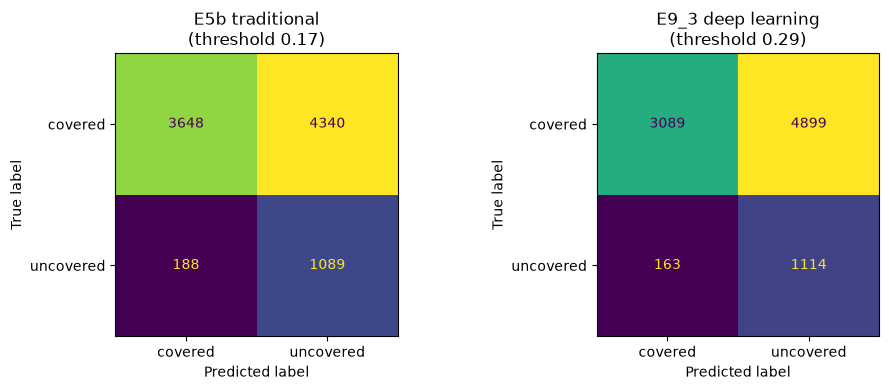

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
panels = [(f"{best_ml_id} traditional", proba_test_ml, threshold_ml),
          (f"{best_dl_id} deep learning", proba_test_dl, threshold_dl)]

for axis, (title, proba, threshold) in zip(axes, panels):
    ConfusionMatrixDisplay.from_predictions(y_test, (proba >= threshold).astype(int),
                                            display_labels=["covered", "uncovered"], ax=axis, colorbar=False)
    axis.set_title(f"{title}\n(threshold {threshold:.2f})")

plt.tight_layout()
plt.savefig("outputs/confusion_matrices.png", dpi=150)
plt.show()



### 13.2 ROC and precision-recall curves

- **ROC curve:** how sensitivity trades against false-alarm rate. The diagonal is random guessing.
- **Precision-recall curve:** how precision falls as we demand higher sensitivity. With rare positives, this is the more honest view.

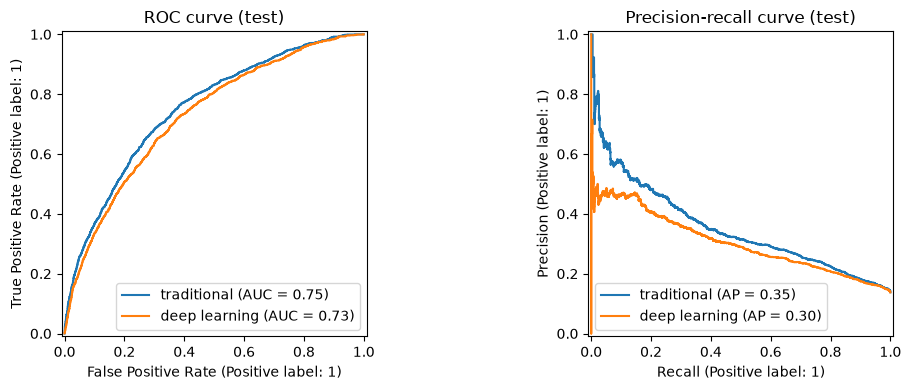

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name, proba in [("traditional", proba_test_ml), ("deep learning", proba_test_dl)]:
    RocCurveDisplay.from_predictions(y_test, proba, name=name, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_test, proba, name=name, ax=axes[1])

axes[0].set_title("ROC curve (test)")
axes[1].set_title("Precision-recall curve (test)")
plt.tight_layout()
plt.savefig("outputs/roc_pr_curves.png", dpi=150)
plt.show()



### 13.3 Learning curves: diagnosing overfitting and underfitting

**Left: the traditional model.** We retrain on 20%, 40%, ... 100% of a sample and plot the score on the training part and on held-out folds. (To keep this step fast it is fitted without class weights, so absolute scores differ slightly from the table.)

**Right: the neural network.** Training loss vs validation loss, epoch by epoch.

How to read them:

| What you see | Diagnosis |
|---|---|
| both curves low and close together | **underfitting** (high bias): the model is too simple |
| training high, validation much lower, large gap | **overfitting** (high variance): the model memorises |
| validation still rising as data grows | more data would help |
| validation loss rising while training loss falls | the network started overfitting at that epoch |

📖 [Learning curves in scikit-learn](https://scikit-learn.org/stable/modules/learning_curve.html)

In [ ]:
sample = train_df.sample(n=min(LC_SUBSAMPLE, len(train_df)), random_state=SEED)

train_sizes, train_scores, val_scores = learning_curve(
    clone(best_ml), sample[best_ml_cols], sample[TARGET].values.astype(int), groups=sample[HOUSEHOLD_ID],
    cv=GroupKFold(n_splits=3), train_sizes=np.linspace(0.2, 1.0, 5), scoring="average_precision", n_jobs=-1)

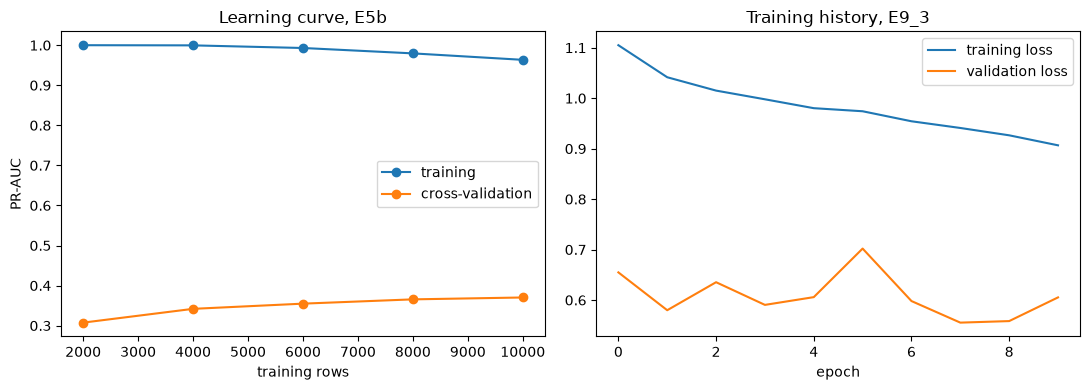

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(train_sizes, train_scores.mean(axis=1), marker="o", label="training")
axes[0].plot(train_sizes, val_scores.mean(axis=1), marker="o", label="cross-validation")
axes[0].set_xlabel("training rows")
axes[0].set_ylabel("PR-AUC")
axes[0].set_title(f"Learning curve, {best_ml_id}")
axes[0].legend()

history = HISTORIES[best_dl_id]
axes[1].plot(history["loss"], label="training loss")
axes[1].plot(history["val_loss"], label="validation loss")
axes[1].set_xlabel("epoch")
axes[1].set_title(f"Training history, {best_dl_id}")
axes[1].legend()

plt.tight_layout()
plt.savefig("outputs/learning_curves.png", dpi=150)
plt.show()

## Step 14: Error analysis

### 14.1 Does the model work equally well for every group?

We compare sensitivity across groups (sex, urban/rural, province, age band) at the chosen cut-off. If the model finds uncovered people in one group but misses them in another, that is a **fairness problem**, not just a metric. Groups with fewer than 20 uncovered people are skipped because their numbers are too noisy.

In [ ]:
def subgroup_report(df: pd.DataFrame, y_true: np.ndarray, proba: np.ndarray, threshold: float,
                    column: str, min_uncovered: int = 20) -> pd.DataFrame:
    rows = []
    values = df[column].values
    for group in pd.unique(values[~pd.isna(values)]):
        in_group = values == group
        actual = y_true[in_group]
        if actual.sum() < min_uncovered:
            continue
        predicted = (proba[in_group] >= threshold).astype(int)
        tp = int(((predicted == 1) & (actual == 1)).sum())
        fn = int(((predicted == 0) & (actual == 1)).sum())
        tn = int(((predicted == 0) & (actual == 0)).sum())
        fp = int(((predicted == 1) & (actual == 0)).sum())
        rows.append({column: group, "n": int(in_group.sum()), "uncovered_n": int(actual.sum()),
                     "sensitivity": round(tp / (tp + fn), 3), "specificity": round(tn / (tn + fp), 3)})
    return pd.DataFrame(rows)

group_columns = [c for c in [SEX_COL, URBAN_COL, PROVINCE_COL, "age_band"] if c and c in test_df.columns]
for column in group_columns:
    print(f"\nBest traditional model by {column}")
    print(subgroup_report(test_df, y_test, proba_test_ml, threshold_ml, column).to_string(index=False))


Best traditional model by s1q1
 s1q1    n  uncovered_n  sensitivity  specificity
    2 4865          650        0.869        0.461
    1 4400          627        0.836        0.452

Best traditional model by ur
 ur    n  uncovered_n  sensitivity  specificity
  1 2479          335        0.836        0.548
  2 6786          942        0.859        0.423

Best traditional model by province
 province    n  uncovered_n  sensitivity  specificity
        1 1114          189        0.820        0.509
        2 2400          357        0.838        0.426
        3 2167          350        0.889        0.395
        4 1626          127        0.724        0.580
        5 1958          254        0.913        0.422

Best traditional model by age_band
 age_band    n  uncovered_n  sensitivity  specificity
        4 1491          190        0.842        0.526
        2 1927          236        0.771        0.496
        1 2277          349        0.894        0.385
        3 1223          145     


### 14.2 Which features matter most?

*Permutation importance* shuffles one feature at a time and measures how much PR-AUC drops. A big drop means the model relied on that feature. We also print each feature's description so you can read it in plain language.

📖 [Permutation importance](https://scikit-learn.org/stable/modules/permutation_importance.html)

In [ ]:
rng = np.random.default_rng(SEED)
subset = rng.choice(len(test_df), size=min(PERM_SUBSAMPLE, len(test_df)), replace=False)

perm = permutation_importance(best_ml, test_df.iloc[subset][best_ml_cols], y_test[subset],
                              scoring="average_precision", n_repeats=3, random_state=SEED, n_jobs=-1)

importance = pd.DataFrame({"feature": best_ml_cols, "importance": perm.importances_mean})
importance = importance.sort_values("importance", ascending=False)
importance["label"] = importance["feature"].map(lambda c: all_labels.get(c, ""))
print(importance.head(15).round(4).to_string(index=False))

       feature  importance                                       label
          exp6      0.0720                Annual Non food Expenditures
         exp11      0.0708                 Use values of durable goods
         exp10      0.0187              Food outside Home Expenditures
         s1q3y      0.0181                                 Age (Years)
            ae      0.0167                                  hhsize A/E
      province      0.0159                                    Province
      district      0.0141                                    District
          exp7      0.0072               Monthly Non food Expenditures
          exp1      0.0062                Total Education Expenditures
          exp2      0.0062                               Imputed Rents
       cons1ae      0.0055                    Aggregate Consumption/ae
          exp8      0.0054              Frequent Non Food Expenditures
         s1q12      0.0052                          Father still alive
      

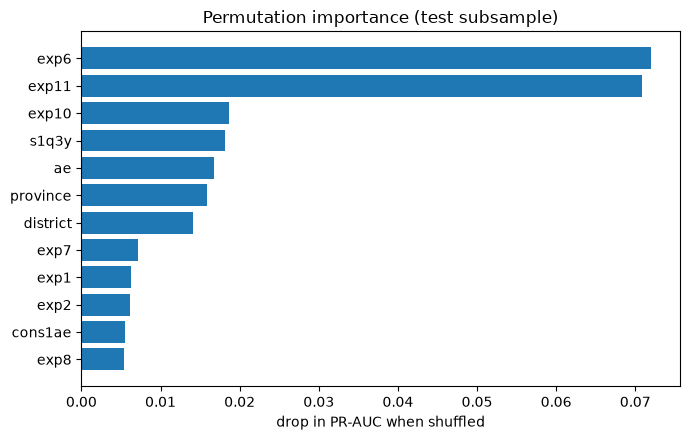

In [ ]:
top_features = importance.head(12).iloc[::-1]

plt.figure(figsize=(7, 4.5))
plt.barh(top_features["feature"], top_features["importance"])
plt.xlabel("drop in PR-AUC when shuffled")
plt.title("Permutation importance (test subsample)")
plt.tight_layout()
plt.savefig("outputs/permutation_importance.png", dpi=150)
plt.show()

## Step 15: Save the models and outputs

These files contain no row-level survey data, so they can go in the shared Google Drive folder. The raw data and any cleaned copy must **not** go on GitHub because of NISR policy or tems that forbids redistribution

| File | Use |
|---|---|
| `models/best_traditional_pipeline.joblib` | the full scikit-learn pipeline (preprocessing and model) |
| `models/deep_learning_preprocessor.joblib` | the preprocessor the neural network needs |
| `models/best_deep_learning.keras` | the trained neural network |
| `outputs/*.csv`, `outputs/*.png` | results tables and figures for the report |

In [ ]:
joblib.dump(best_ml, "models/best_traditional_pipeline.joblib")
joblib.dump(dl_preprocessor, "models/deep_learning_preprocessor.joblib")
best_dl.save("models/best_deep_learning.keras")

results.to_csv("outputs/experiment_results.csv", index=False)
final.to_csv("outputs/final_test_results.csv", index=False)
importance.head(30).to_csv("outputs/permutation_importance.csv", index=False)

print("Saved models:", sorted(os.listdir("models")))
print("Saved outputs:", sorted(os.listdir("outputs")))

Saved models: ['best_deep_learning.keras', 'best_traditional_pipeline.joblib', 'deep_learning_preprocessor.joblib']
Saved outputs: ['confusion_matrices.png', 'experiment_results.csv', 'final_test_results.csv', 'learning_curves.png', 'permutation_importance.csv', 'permutation_importance.png', 'roc_pr_curves.png']


## Discussion section

1. **Which single change moved validation PR-AUC the most, and which moved it the least (or hurt it)?**

Removing the welfare variables moved the score the most and it moved the score from 0.412(E2) to 0.313(E6a) hence the change is about 0.099.And the biggest change from changing models for example changing the model rom logistic regression(0.352) to gradient boosting (0.412) so the gain is about 0.06. And on the small changes was caused by engineered features where it was 0.416 without them and then 0.412 with them. The differences under about 0.01 are probably not that crucial


2. **Compare E7 and E8 with the tuned tree model E4.** Use the learning curves to explain any gap (bias or variance?).


The networks score changed from 0.364 to 0.374 and E4 scored 0.424 there is about 0.05 change or more. Learning curve shows high variange with training PR-AUC near 1.0 and a cross validation of 0.31 to 0.37. the Regularization helped the trees since E4 used a low learning and large leaves.For the networks the evidence is sort of weaker. All eight regularization and learning rate settings landed in the same narrow band so the more variance control do not help. That directed a simple overfitting and towards a limit in the model class or in the information provided in the features.


3. **Compare E3 with E6a.** What can you honestly say about poverty and coverage, given that consumption may include premiums paid?


You can honestly say that welfare carry most of the signal: removing them cuts PR-AUC by about a quarter.The uncovered share also falls steadily from 23.3% in the poorest quintile(group) to 6.8% in the richest.
the consumption might include premiums paid,but the signal remains even when you drop the non-food spending totals(0.366) and all spending totals (E6d,0.357). the durable can't say poverty causes non-coverage or that premiums aren't involved. The surveys association only. E6a is still 2.3 times the base rate and so demographics and geography carry some signal too.


4. **At the chosen threshold, what does a false alarm cost, and what does a missed person cost?** Which would a ministry or an insurer care about more?


At the test threshold, the boosted model flagged about 4,340 covered people to find 1,089 uncovered people about four wasted contracts per personl found and it missed 188.A false alarm costs staff some time and wasted outreach.A missed person stays uncovered and and in your data uncovered ill people consulted a provider far less often (about 40% against 74%) though that's just association.
A ministry is likely to care more about missed people since it's aims is the universal coverage.An insurer is more likely to weigh outreach cost and false alarms. The right trade-off depends on how cheap a contract is: if it's text message,false alsrms are cheap and high sensitivity is justified.
5. **What can this household survey *not* tell us?** (Think: why someone is uncovered, or whether a premium lapsed.) What would you collect next?

It can't tell why someone is uncovered whether a person never enrolled or let a premium lapse whether they were covered at the moment they got ill or what changes over time since it's cross sectional and unweighted.I'd collect next administrative enrollment and payment records linked to households and short follow-up questions on reasons for not enrollment or lapse,premium category and the next survey round to test whether the model holds up over time.

